# WisdomNet — Breast Cancer Wisconsin Dataset

The paper reports a **30–16–2 MLP** and a **30–16–3 WisdomNet**, with 512 training and 57 test samples. For Breast Cancer, it reports 1.76% base error, 0% WisdomNet error, and a 10.05% reject rate.


**Goal:** Train a normal classifier, find the training samples it gets wrong, then add one new output neuron that learns to say **"reject"** on inputs like those.

> **Implementation note:** scikit-learn uses one output neuron for binary `MLPClassifier`. I therefore trained the equivalent binary network and mathematically mirror its final neuron into two class outputs before adding the reject neuron. The equivalence is checked before fine-tuning.


### Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import ConfusionMatrixDisplay

SEED = 0
np.random.seed(SEED)


### Load Data


In [2]:
X, y = load_breast_cancer(return_X_y=True)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=57, random_state=SEED, stratify=y
)

scaler = StandardScaler().fit(X_train)
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)

print(f"Train: {len(X_train)}   Test: {len(X_test)}")


Train: 512   Test: 57


### EDA

Malignant    212
Benign       357
Name: Count, dtype: int64


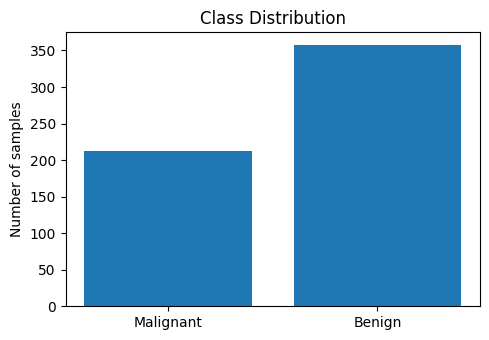

In [3]:
class_names = ["Malignant", "Benign"]
class_counts = np.bincount(y)
print(pd.Series(class_counts, index=class_names, name="Count"))

plt.figure(figsize=(5, 3.5))
plt.bar(class_names, class_counts)
plt.ylabel("Number of samples")
plt.title("Class Distribution")
plt.tight_layout()
plt.show()

## WisdomNet Architecture

### Step-1: Train the Base Network *N*

One hidden layer, 16 neurons (paper's `30-16-2` architecture)


In [4]:
N = MLPClassifier(
    hidden_layer_sizes=(16,),
    activation="logistic",
    solver="sgd",
    learning_rate_init=0.1,
    max_iter=500,
    random_state=SEED
)
N.fit(X_train, y_train)

base_preds = N.predict(X_test)
base_error = np.mean(base_preds != y_test)
base_accuracy = 1 - base_error

print(f"Base network N — test error: {base_error * 100:.2f}%")
print(f"Base network N — test accuracy: {base_accuracy * 100:.2f}%")

Base network N — test error: 1.75%
Base network N — test accuracy: 98.25%


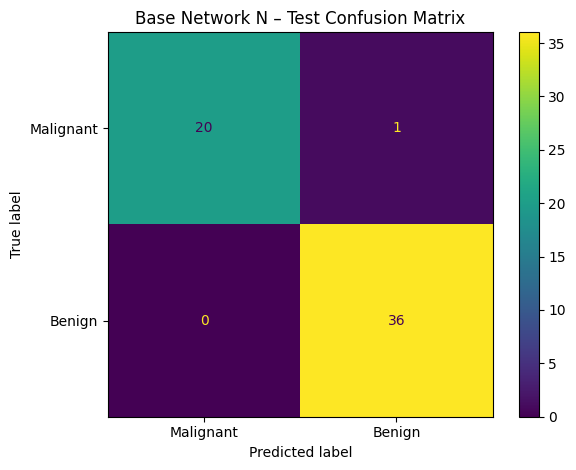

In [5]:
ConfusionMatrixDisplay.from_predictions(
    y_test, base_preds, display_labels=class_names
)
plt.title("Base Network N – Test Confusion Matrix")
plt.tight_layout()
plt.show()

### Step-2: Create the Reject Set

Classify the training set with *N* and collect every sample it gets
wrong. These will be relabeled `reject`.


In [6]:
train_preds = N.predict(X_train)
reject_mask = train_preds != y_train
X_reject = X_train[reject_mask]

print(f"Misclassified training samples: {len(X_reject)} / {len(X_train)}")
if len(X_reject) == 0:
    raise ValueError("No misclassified training samples; the reject set is empty.")


Misclassified training samples: 5 / 512


### Step-3: Build WisdomNet W

The paper keeps the trained base-network parameters, adds one conjugate neuron, and initializes the new neuron’s incoming weights and bias to zero.

For the binary scikit-learn model, the single sigmoid output is mirrored using `sigmoid(-z) = 1 - sigmoid(z)`. This gives two equivalent class outputs before fine-tuning.


In [7]:
def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

def forward(X, W1, b1, W2, b2):
    hidden = sigmoid(X @ W1 + b1)
    output = sigmoid(hidden @ W2 + b2)
    return output, hidden

# Transfer N's trained parameters
W1_0 = N.coefs_[0].copy()
b1_0 = N.intercepts_[0].copy()
w_single = N.coefs_[1].ravel().copy()
b_single = N.intercepts_[1][0].copy()

# Mirror into two equivalent outputs: [malignant, benign]
W2_0 = np.column_stack([-w_single, w_single])
b2_0 = np.array([-b_single, b_single])

# Add the zero-initialized reject neuron
W2_0 = np.hstack([W2_0, np.zeros((W2_0.shape[0], 1))])
b2_0 = np.append(b2_0, 0.0)

initial_weights = (W1_0.copy(), b1_0.copy(), W2_0.copy(), b2_0.copy())

# Equivalence check before fine-tuning
w_probs, _ = forward(X_test, W1_0, b1_0, W2_0[:, :2], b2_0[:2])
w_preds = np.argmax(w_probs, axis=1)
print("W matches N before fine-tuning:", np.array_equal(w_preds, base_preds))


W matches N before fine-tuning: True


### Step-4: Fine-tune *W* on the Reject Set

All parameters are updated, using only the misclassified training
samples, now labeled `reject`. I've used **10 epochs** (for reason refer to sensitivity analysis section).


In [8]:
def fine_tune(X_r, W1, b1, W2, b2, epochs=10, lr=0.3):
    y_r = np.zeros((len(X_r), 3))
    y_r[:, 2] = 1.0

    for _ in range(epochs):
        output, hidden = forward(X_r, W1, b1, W2, b2)
        d_out = (output - y_r) * output * (1 - output)
        d_hidden = (d_out @ W2.T) * hidden * (1 - hidden)

        W2 -= lr * (hidden.T @ d_out) / len(X_r)
        b2 -= lr * d_out.mean(axis=0)
        W1 -= lr * (X_r.T @ d_hidden) / len(X_r)
        b1 -= lr * d_hidden.mean(axis=0)

    return W1, b1, W2, b2

W1, b1, W2, b2 = fine_tune(X_reject, *[w.copy() for w in initial_weights])
print("Fine-tuning done.")


Fine-tuning done.


### Evaluate

Paper's definitions: **Error** = (FP + FN) / N and **Reject rate** = R / N, where N is the *total* test set (rejected samples count toward N, not just toward decided predictions).


In [9]:
def evaluate_wisdomnet(X, y, W1, b1, W2, b2):
    probs, _ = forward(X, W1, b1, W2, b2)
    class_scores, reject_score = probs[:, :2], probs[:, 2]

    pred_class = np.argmax(class_scores, axis=1)
    is_reject = reject_score > class_scores.max(axis=1)
    wrong = ~is_reject & (pred_class != y)

    return {
        "pred_class": pred_class,
        "is_reject": is_reject,
        "error_rate": wrong.mean(),
        "reject_rate": is_reject.mean(),
    }

result = evaluate_wisdomnet(X_test, y_test, W1, b1, W2, b2)

print(f"{'Model':<15}{'Error rate':>12}{'Reject rate':>14}")
print(f"{'Base N':<15}{base_error * 100:>11.2f}%{'--':>14}")
print(f"{'WisdomNet W':<15}{result['error_rate'] * 100:>11.2f}%{result['reject_rate'] * 100:>13.2f}%")


Model            Error rate   Reject rate
Base N                1.75%            --
WisdomNet W           0.00%         7.02%


### Result chart

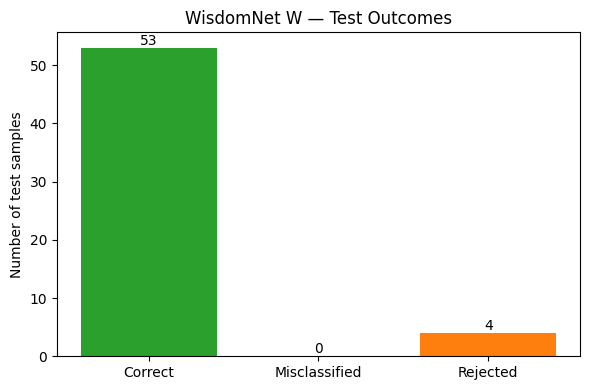

In [10]:
pred_class, is_reject = result["pred_class"], result["is_reject"]

correct_W = np.sum(~is_reject & (pred_class == y_test))
wrong_W = np.sum(~is_reject & (pred_class != y_test))
reject_W = np.sum(is_reject)

labels = ["Correct", "Misclassified", "Rejected"]
counts = [correct_W, wrong_W, reject_W]

plt.figure(figsize=(6, 4))
plt.bar(labels, counts, color=["tab:green", "tab:red", "tab:orange"])
plt.ylabel("Number of test samples")
plt.title("WisdomNet W — Test Outcomes")
for i, count in enumerate(counts):
    plt.text(i, count + 0.5, str(count), ha="center")
plt.tight_layout()
plt.savefig("wisdomnet_breast_cancer_results.png", dpi=150)
plt.show()


### Sensitivity Analysis: How Long Should We Fine-tune?

The paper leaves this unresolved: training too long risks excess rejection, stopping too early may miss doubtful cases. I've started
every run from the **same pre-fine-tuning W** and vary only the number of epochs.


In [11]:
epoch_grid = [1, 2, 5, 10, 20, 40, 80, 160]
rows = []

for epochs in epoch_grid:
    W1_e, b1_e, W2_e, b2_e = fine_tune(X_reject, *[w.copy() for w in initial_weights], epochs=epochs)
    r = evaluate_wisdomnet(X_test, y_test, W1_e, b1_e, W2_e, b2_e)
    rows.append({
        "Epochs": epochs,
        "Error rate (%)": 100 * r["error_rate"],
        "Reject rate (%)": 100 * r["reject_rate"],
    })

sensitivity = pd.DataFrame(rows)
sensitivity


,Epochs,Error rate (%),Reject rate (%)
0,1,1.754386,0.000000
1,2,1.754386,0.000000
2,5,1.754386,1.754386
3,10,0.000000,7.017544
4,20,0.000000,15.789474
5,40,0.000000,45.614035
6,80,0.000000,59.649123
7,160,0.000000,64.912281


**Why 10 epochs:** it's the earliest point where error reaches 0%, with
the lowest reject rate among all zero-error settings. Beyond 10 epochs,
error stays at 0% but reject rate keeps climbing (extra fine-tuning
only rejects more samples without improving accuracy).
